In [1]:
# =====================================================
# EXPERIMENT 5
# PART 1: DATASET PREPARATION
# SAME DATASET TRAIN TEST VALIDATION
# =====================================================

import pandas as pd
import numpy as np


print("="*70)
print("EXPERIMENT 5")
print("SAME DATASET TRAIN TEST VALIDATION")
print("PART 1: DATASET PREPARATION")
print("="*70)


# =====================================================
# LOAD DATASET
# =====================================================

dataset = pd.read_csv(
    "../data/train_test_network.csv"
)


print(
    "Original Dataset Shape:",
    dataset.shape
)



# =====================================================
# CLEAN DATASET
# =====================================================

dataset.replace(
    "-",
    "unknown",
    inplace=True
)


dataset.fillna(
    "unknown",
    inplace=True
)



print(
    "Cleaning Completed"
)



# =====================================================
# DROP UNUSED FEATURES
# SAME AS ALL EXPERIMENTS
# =====================================================


drop_columns = [

    "src_ip",
    "dst_ip",

    "src_port",
    "dst_port",

    "ssl_subject",
    "ssl_issuer",

    "http_user_agent",

    "label"

]


dataset.drop(

    columns=drop_columns,

    inplace=True,

    errors="ignore"

)



print(
    "After Feature Removal:",
    dataset.shape
)



print("\nClass Distribution")

print(
    dataset["type"].value_counts()
)



print("\n")

print("="*70)
print("PART 1 COMPLETED")
print("="*70)

EXPERIMENT 5
SAME DATASET TRAIN TEST VALIDATION
PART 1: DATASET PREPARATION
Original Dataset Shape: (211043, 44)
Cleaning Completed
After Feature Removal: (211043, 36)

Class Distribution
type
normal        50000
backdoor      20000
ddos          20000
dos           20000
injection     20000
password      20000
ransomware    20000
scanning      20000
xss           20000
mitm           1043
Name: count, dtype: int64


PART 1 COMPLETED


In [2]:
# =====================================================
# EXPERIMENT 5
# PART 2:
# COMMON DATA SPLIT AND PREPROCESSING
# =====================================================


from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    LabelEncoder
)

from sklearn.compose import ColumnTransformer

from sklearn.model_selection import train_test_split



print("="*70)
print("PART 2: PREPROCESSING")
print("="*70)



# =====================================================
# FEATURES AND LABEL
# =====================================================


X = dataset.drop(
    "type",
    axis=1
)


y = dataset["type"]



# =====================================================
# LABEL ENCODING
# =====================================================


label_encoder = LabelEncoder()


y_encoded = label_encoder.fit_transform(
    y
)



print(
    "Classes:",
    label_encoder.classes_
)



# =====================================================
# FEATURE TYPES
# =====================================================


categorical_columns = X.select_dtypes(

    include="object"

).columns.tolist()



numerical_columns = X.select_dtypes(

    exclude="object"

).columns.tolist()



print(
    "Categorical:",
    len(categorical_columns)
)


print(
    "Numerical:",
    len(numerical_columns)
)



# =====================================================
# DATA TYPE FIX
# =====================================================


for col in categorical_columns:

    X[col] = X[col].astype(str)



for col in numerical_columns:

    X[col] = pd.to_numeric(

        X[col],

        errors="coerce"

    )



X[numerical_columns] = (

    X[numerical_columns]

    .fillna(0)

)



# =====================================================
# COMMON STRATIFIED SPLIT
# USED BY ALL MODELS
# =====================================================


X_train, X_test, y_train, y_test = train_test_split(

    X,

    y_encoded,

    test_size=0.20,

    random_state=42,

    stratify=y_encoded

)



print("\nTrain Shape:")
print(X_train.shape)


print("\nTest Shape:")
print(X_test.shape)



# =====================================================
# PREPROCESSOR
# =====================================================


preprocessor = ColumnTransformer(

    transformers=[


        (
            "cat",

            OneHotEncoder(

                handle_unknown="ignore",

                sparse_output=False

            ),

            categorical_columns

        ),


        (
            "num",

            StandardScaler(),

            numerical_columns

        )


    ]

)



# =====================================================
# FIT ONLY TRAIN DATA
# =====================================================


X_train_processed = preprocessor.fit_transform(

    X_train

)


X_test_processed = preprocessor.transform(

    X_test

)



print("\nProcessed Shape")

print(
    X_train_processed.shape
)


print(
    X_test_processed.shape
)



print("\n")

print("="*70)
print("PART 2 COMPLETED")
print("="*70)

PART 2: PREPROCESSING
Classes: ['backdoor' 'ddos' 'dos' 'injection' 'mitm' 'normal' 'password'
 'ransomware' 'scanning' 'xss']
Categorical: 21
Numerical: 14


C:\Users\Kruthik Raj M\AppData\Local\Temp\ipykernel_14792\3309568910.py:67: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(



Train Shape:
(168834, 35)

Test Shape:
(42209, 35)

Processed Shape
(168834, 874)
(42209, 874)


PART 2 COMPLETED


In [3]:

# # =====================================================
# # EXPERIMENT 2
# # PART 5: BI-LSTM HOLD-OUT VALIDATION
# # TRAINING + VALIDATION MONITORING
# # =====================================================


# import torch
# import torch.nn as nn

# from torch.utils.data import TensorDataset, DataLoader

# import numpy as np


# from sklearn.metrics import (
#     accuracy_score,
#     precision_score,
#     recall_score,
#     f1_score,
#     classification_report
# )


# from sklearn.utils.class_weight import compute_class_weight



# print("="*70)
# print("EXPERIMENT 2")
# print("PART 5: BI-LSTM")
# print("="*70)




# # =====================================================
# # TRAIN TEST SPLIT
# # SAME AS RF/XGBOOST
# # =====================================================


# X_train, X_test, y_train, y_test = train_test_split(

#     X,

#     y_encoded,

#     test_size=0.20,

#     random_state=42,

#     stratify=y_encoded

# )



# # =====================================================
# # PREPROCESSING
# # SAME AS ORIGINAL PIPELINE
# # =====================================================


# X_train_processed = preprocessor.fit_transform(

#     X_train

# )


# X_test_processed = preprocessor.transform(

#     X_test

# )



# print(
#     "Processed Shape:",
#     X_train_processed.shape
# )




# # =====================================================
# # CONVERT DATA
# # =====================================================


# X_train_np = np.asarray(

#     X_train_processed,

#     dtype=np.float32

# )


# X_test_np = np.asarray(

#     X_test_processed,

#     dtype=np.float32

# )



# y_train_np = np.asarray(

#     y_train,

#     dtype=np.int64

# )


# y_test_np = np.asarray(

#     y_test,

#     dtype=np.int64

# )




# # =====================================================
# # LSTM RESHAPE
# # samples,timestep,features
# # =====================================================


# X_train_lstm = X_train_np.reshape(

#     X_train_np.shape[0],

#     1,

#     X_train_np.shape[1]

# )



# X_test_lstm = X_test_np.reshape(

#     X_test_np.shape[0],

#     1,

#     X_test_np.shape[1]

# )



# print(

#     "LSTM Input Shape:",

#     X_train_lstm.shape

# )




# # =====================================================
# # TENSORS
# # =====================================================


# X_train_tensor = torch.tensor(

#     X_train_lstm

# )


# y_train_tensor = torch.tensor(

#     y_train_np

# )



# X_test_tensor = torch.tensor(

#     X_test_lstm

# )


# y_test_tensor = torch.tensor(

#     y_test_np

# )




# # =====================================================
# # DATA LOADER
# # =====================================================


# train_dataset = TensorDataset(

#     X_train_tensor,

#     y_train_tensor

# )



# train_loader = DataLoader(

#     train_dataset,

#     batch_size=128,

#     shuffle=True

# )




# # =====================================================
# # CLASS WEIGHTS
# # =====================================================


# class_weights = compute_class_weight(

#     class_weight="balanced",

#     classes=np.unique(y_train_np),

#     y=y_train_np

# )



# class_weights = torch.tensor(

#     class_weights,

#     dtype=torch.float32

# )



# # =====================================================
# # BI-LSTM MODEL
# # =====================================================


# class BiLSTM_IDS(nn.Module):


#     def __init__(self,input_size,num_classes):

#         super().__init__()


#         self.lstm1 = nn.LSTM(

#             input_size,

#             128,

#             batch_first=True,

#             bidirectional=True

#         )


#         self.dropout1 = nn.Dropout(0.3)



#         self.lstm2 = nn.LSTM(

#             256,

#             64,

#             batch_first=True,

#             bidirectional=True

#         )


#         self.dropout2 = nn.Dropout(0.3)



#         self.fc1 = nn.Linear(

#             128,

#             64

#         )


#         self.bn = nn.BatchNorm1d(64)


#         self.dropout3 = nn.Dropout(0.3)



#         self.output = nn.Linear(

#             64,

#             num_classes

#         )




#     def forward(self,x):


#         x,_ = self.lstm1(x)


#         x = self.dropout1(x)



#         x,_ = self.lstm2(x)



#         x = x[:,-1,:]



#         x = self.dropout2(x)



#         x = torch.relu(

#             self.bn(

#                 self.fc1(x)

#             )

#         )



#         x = self.dropout3(x)



#         return self.output(x)





# # =====================================================
# # INITIALIZE MODEL
# # =====================================================


# model = BiLSTM_IDS(

#     X_train_lstm.shape[2],

#     len(label_encoder.classes_)

# )



# print(model)




# # =====================================================
# # LOSS OPTIMIZER
# # =====================================================


# criterion = nn.CrossEntropyLoss(

#     weight=class_weights

# )



# optimizer = torch.optim.AdamW(

#     model.parameters(),

#     lr=0.001,

#     weight_decay=1e-5

# )



# scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(

#     optimizer,

#     patience=3,

#     factor=0.5

# )




# # =====================================================
# # STORE HISTORY
# # =====================================================


# train_losses = []

# train_accuracies = []

# val_losses = []

# val_accuracies = []




# # =====================================================
# # TRAINING
# # =====================================================


# epochs = 30



# print("\nTraining Bi-LSTM")



# for epoch in range(epochs):


#     model.train()


#     running_loss = 0

#     correct = 0

#     total = 0



#     for batch_x,batch_y in train_loader:


#         optimizer.zero_grad()



#         output = model(batch_x)



#         loss = criterion(

#             output,

#             batch_y

#         )



#         loss.backward()

#         optimizer.step()



#         running_loss += loss.item()



#         pred = torch.argmax(

#             output,

#             dim=1

#         )



#         correct += (

#             pred == batch_y

#         ).sum().item()


#         total += batch_y.size(0)




#     train_loss = running_loss / len(train_loader)

#     train_acc = correct / total




#     # ==============================
#     # VALIDATION
#     # ==============================


#     model.eval()


#     with torch.no_grad():


#         val_output = model(

#             X_test_tensor

#         )


#         val_loss = criterion(

#             val_output,

#             y_test_tensor

#         ).item()



#         val_pred = torch.argmax(

#             val_output,

#             dim=1

#         )



#         val_acc = (

#             val_pred == y_test_tensor

#         ).sum().item() / len(y_test_tensor)




#     train_losses.append(train_loss)

#     train_accuracies.append(train_acc)

#     val_losses.append(val_loss)

#     val_accuracies.append(val_acc)



#     scheduler.step(val_loss)



#     print(

#         f"Epoch {epoch+1}/{epochs} | "

#         f"Train Loss:{train_loss:.4f} | "

#         f"Train Acc:{train_acc:.4f} | "

#         f"Val Loss:{val_loss:.4f} | "

#         f"Val Acc:{val_acc:.4f}"

#     )




# # =====================================================
# # FINAL TEST RESULTS
# # =====================================================


# model.eval()


# with torch.no_grad():

#     output = model(

#         X_test_tensor

#     )


#     predictions = torch.argmax(

#         output,

#         dim=1

#     ).numpy()




# print("\n")

# print("="*70)

# print("BI-LSTM FINAL RESULTS")

# print("="*70)



# print(

# "Accuracy:",

# accuracy_score(y_test_np,predictions)

# )



# print(

# "Precision:",

# precision_score(

# y_test_np,

# predictions,

# average="weighted",

# zero_division=0

# )

# )



# print(

# "Recall:",

# recall_score(

# y_test_np,

# predictions,

# average="weighted",

# zero_division=0

# )

# )



# print(

# "F1 Score:",

# f1_score(

# y_test_np,

# predictions,

# average="weighted",

# zero_division=0

# )

# )
# -


# print(

# classification_report(

# y_test_np,

# predictions,

# target_names=label_encoder.classes_,

# digits=4,

# zero_division=0

# )

# )

# =====================================================
# EXPERIMENT 2
# PART 5: LSTM TRAIN TEST VALIDATION
# =====================================================


import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    LSTM,
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)


print("="*70)
print("EXPERIMENT 2")
print("PART 5: LSTM MODEL")
print("="*70)



# =====================================================
# TRAIN TEST SPLIT
# SAME RANDOM STATE
# =====================================================


# X_train, X_test, y_train, y_test = train_test_split(

#     X,

#     y_encoded,

#     test_size=0.20,

#     random_state=42,

#     stratify=y_encoded

# )



# =====================================================
# PREPROCESSING
# =====================================================


X_train_processed = preprocessor.fit_transform(

    X_train

)


X_test_processed = preprocessor.transform(

    X_test

)



print(
    "Processed Shape:",
    X_train_processed.shape
)



# =====================================================
# RESHAPE FOR LSTM
# =====================================================


X_train_lstm = np.reshape(

    X_train_processed,

    (
        X_train_processed.shape[0],
        1,
        X_train_processed.shape[1]
    )

)


X_test_lstm = np.reshape(

    X_test_processed,

    (
        X_test_processed.shape[0],
        1,
        X_test_processed.shape[1]
    )

)



print(
    "LSTM Input Shape:",
    X_train_lstm.shape
)



# =====================================================
# BUILD LSTM MODEL
# =====================================================


num_classes = len(label_encoder.classes_)


lstm_model = Sequential()



lstm_model.add(

    LSTM(

        128,

        return_sequences=True,

        input_shape=(

            1,

            X_train_processed.shape[1]

        )

    )

)



lstm_model.add(

    Dropout(0.3)

)



lstm_model.add(

    LSTM(

        64

    )

)



lstm_model.add(

    Dropout(0.3)

)



lstm_model.add(

    Dense(

        64,

        activation="relu"

    )

)



lstm_model.add(

    BatchNormalization()

)



lstm_model.add(

    Dense(

        num_classes,

        activation="softmax"

    )

)



# =====================================================
# COMPILE
# =====================================================


lstm_model.compile(

    optimizer="adam",

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)



lstm_model.summary()



# =====================================================
# CALLBACKS
# =====================================================


early_stop = EarlyStopping(

    monitor="val_loss",

    patience=5,

    restore_best_weights=True

)



reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=3

)



# =====================================================
# TRAIN
# =====================================================


history = lstm_model.fit(

    X_train_lstm,

    y_train,

    epochs=30,

    batch_size=128,

    validation_split=0.2,

    callbacks=[

        early_stop,

        reduce_lr

    ],

    verbose=1

)



# =====================================================
# PREDICTION
# =====================================================


lstm_predictions = np.argmax(

    lstm_model.predict(

        X_test_lstm

    ),

    axis=1

)



# =====================================================
# RESULTS
# =====================================================


print("\n")

print("="*70)

print("LSTM RESULTS")

print("="*70)



print(

    "Accuracy:",

    accuracy_score(

        y_test,

        lstm_predictions

    )

)


print(

    "Precision:",

    precision_score(

        y_test,

        lstm_predictions,

        average="weighted",

        zero_division=0

    )

)



print(

    "Recall:",

    recall_score(

        y_test,

        lstm_predictions,

        average="weighted",

        zero_division=0

    )

)



print(

    "F1 Score:",

    f1_score(

        y_test,

        lstm_predictions,

        average="weighted",

        zero_division=0

    )

)



print("\nClassification Report")

print(

    classification_report(

        y_test,

        lstm_predictions,

        target_names=label_encoder.classes_,

        digits=4,

        zero_division=0

    )

)

EXPERIMENT 2
PART 5: LSTM MODEL
Processed Shape: (168834, 874)
LSTM Input Shape: (168834, 1, 874)


c:\Users\Kruthik Raj M\anaconda3\envs\hiot_ids\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 1, 128)         │       513,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 568,010 (2.17 MB)

 Trainable params: 567,882 (2.17 MB)

 Non-trainable params: 128 (512.00 B)

Epoch 1/30
1056/1056 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.6928 - loss: 0.7611 - val_accuracy: 0.7154 - val_loss: 0.6616 - learning_rate: 0.0010
Epoch 2/30
1056/1056 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.7276 - loss: 0.6586 - val_accuracy: 0.7077 - val_loss: 0.7084 - learning_rate: 0.0010
Epoch 3/30
1056/1056 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.7376 - loss: 0.6293 - val_accuracy: 0.7582 - val_loss: 0.5842 - learning_rate: 0.0010
Epoch 4/30
1056/1056 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.7524 - loss: 0.6007 - val_accuracy: 0.7740 - val_loss: 0.5694 - learning_rate: 0.0010
Epoch 5/30
1056/1056 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.7677 - loss: 0.5703 - val_accuracy: 0.7963 - val_loss: 0.5313 - learning_rate: 0.0010
Epoch 6/30
1056/1056 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.7769 - loss: 0.5483 - val_accuracy: 0.7850 - val_loss: 0.5409 - learning_rate: 0.0010
Epoch 7/30
1056/1056 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.7849 - 

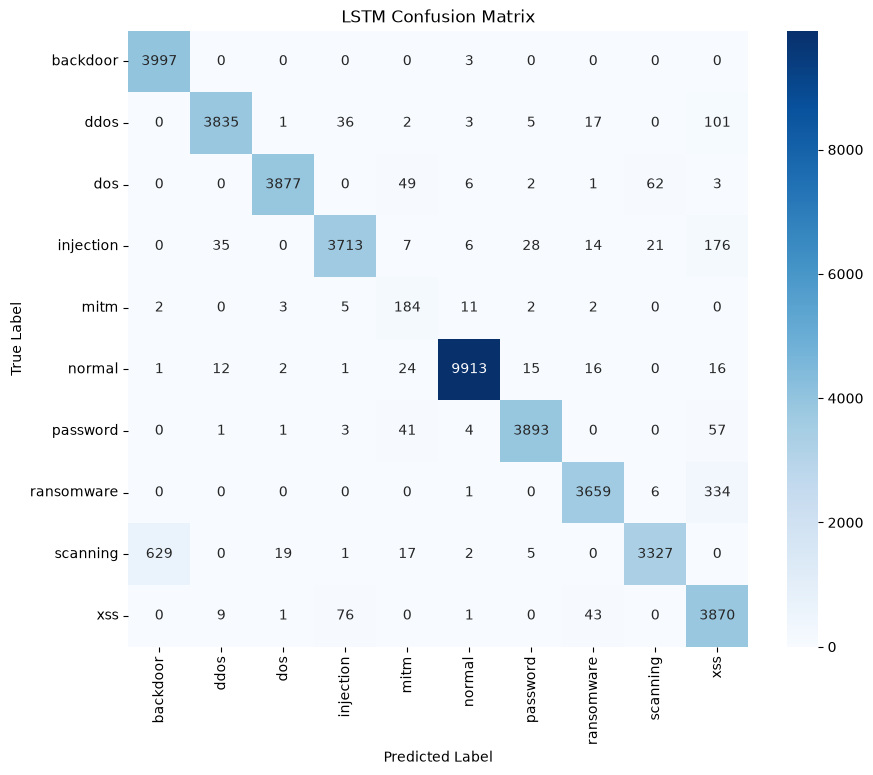

GRAPHS GENERATED


In [4]:
# # =====================================================
# # EXPERIMENT 2
# # PART 6: BI-LSTM TRAINING CURVES
# # =====================================================


# import matplotlib.pyplot as plt



# print("="*70)

# print("BI-LSTM LEARNING CURVES")

# print("="*70)



# epochs_range = range(1,len(train_losses)+1)



# # LOSS CURVE

# plt.figure(figsize=(8,5))


# plt.plot(

#     epochs_range,

#     train_losses,

#     label="Training Loss"

# )


# plt.plot(

#     epochs_range,

#     val_losses,

#     label="Validation Loss"

# )



# plt.xlabel("Epoch")

# plt.ylabel("Loss")

# plt.title("Bi-LSTM Training and Validation Loss")

# plt.legend()

# plt.grid()

# plt.show()




# # ACCURACY CURVE


# plt.figure(figsize=(8,5))


# plt.plot(

#     epochs_range,

#     train_accuracies,

#     label="Training Accuracy"

# )



# plt.plot(

#     epochs_range,

#     val_accuracies,

#     label="Validation Accuracy"

# )



# plt.xlabel("Epoch")

# plt.ylabel("Accuracy")


# plt.title("Bi-LSTM Training and Validation Accuracy")


# plt.legend()


# plt.grid()


# plt.show()



# print("="*70)

# print("BI-LSTM VISUALIZATION COMPLETED")

# print("="*70)
# =====================================================
# LSTM TRAINING HISTORY VISUALIZATION
# =====================================================


import matplotlib.pyplot as plt



# print("="*70)
# print("LSTM TRAINING GRAPHS")
# print("="*70)



# # =====================================================
# # ACCURACY GRAPH
# # =====================================================


# plt.figure(figsize=(8,5))


# plt.plot(

#     history.history["accuracy"],

#     label="Training Accuracy"

# )


# plt.plot(

#     history.history["val_accuracy"],

#     label="Validation Accuracy"

# )


# plt.xlabel("Epochs")

# plt.ylabel("Accuracy")

# plt.title(
#     "LSTM Training and Validation Accuracy"
# )


# plt.legend()

# plt.grid(True)


# plt.show()



# # =====================================================
# # LOSS GRAPH
# # =====================================================


# plt.figure(figsize=(8,5))


# plt.plot(

#     history.history["loss"],

#     label="Training Loss"

# )


# plt.plot(

#     history.history["val_loss"],

#     label="Validation Loss"

# )



# plt.xlabel("Epochs")

# plt.ylabel("Loss")


# plt.title(
#     "LSTM Training and Validation Loss"
# )



# plt.legend()

# plt.grid(True)


# plt.show()



# =====================================================
# CONFUSION MATRIX
# =====================================================


from sklearn.metrics import confusion_matrix

import seaborn as sns



cm = confusion_matrix(

    y_test,

    lstm_predictions

)



plt.figure(figsize=(10,8))


sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=label_encoder.classes_,

    yticklabels=label_encoder.classes_

)



plt.xlabel(
    "Predicted Label"
)


plt.ylabel(
    "True Label"
)


plt.title(
    "LSTM Confusion Matrix"
)


plt.show()



print("="*70)

print("GRAPHS GENERATED")

print("="*70)

In [5]:
# =====================================================
# EXPERIMENT 2
# PART 6: IMPROVED MLP MODEL
# =====================================================


import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.regularizers import l2

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)



print("="*70)
print("EXPERIMENT 2")
print("PART 6: IMPROVED MLP MODEL")
print("="*70)



# =====================================================
# TRAIN TEST SPLIT
# =====================================================


# X_train, X_test, y_train, y_test = train_test_split(

#     X,

#     y_encoded,

#     test_size=0.20,

#     random_state=42,

#     stratify=y_encoded

# )



# =====================================================
# PREPROCESSING
# =====================================================


X_train_processed = preprocessor.fit_transform(

    X_train

)


X_test_processed = preprocessor.transform(

    X_test

)



print(
    "MLP Input Shape:",
    X_train_processed.shape
)



# =====================================================
# BUILD IMPROVED MLP
# =====================================================


num_classes = len(label_encoder.classes_)



mlp_model = Sequential()



# Input + First Hidden Layer

mlp_model.add(

    Dense(

        512,

        activation="relu",

        kernel_regularizer=l2(0.0001),

        input_shape=(

            X_train_processed.shape[1],

        )

    )

)


mlp_model.add(

    BatchNormalization()

)


mlp_model.add(

    Dropout(0.4)

)



# Second Hidden Layer


mlp_model.add(

    Dense(

        256,

        activation="relu",

        kernel_regularizer=l2(0.0001)

    )

)


mlp_model.add(

    BatchNormalization()

)


mlp_model.add(

    Dropout(0.3)

)



# Third Hidden Layer


mlp_model.add(

    Dense(

        128,

        activation="relu"

    )

)


mlp_model.add(

    Dropout(0.3)

)



# Fourth Hidden Layer


mlp_model.add(

    Dense(

        64,

        activation="relu"

    )

)



# Output Layer


mlp_model.add(

    Dense(

        num_classes,

        activation="softmax"

    )

)



mlp_model.summary()



# =====================================================
# COMPILE
# =====================================================


mlp_model.compile(

    optimizer=tf.keras.optimizers.Adam(

        learning_rate=0.001

    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)



# =====================================================
# CALLBACKS
# =====================================================


early_stop = EarlyStopping(

    monitor="val_loss",

    patience=7,

    restore_best_weights=True

)



reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=3,

    min_lr=1e-6

)



# =====================================================
# TRAIN
# =====================================================


history_mlp = mlp_model.fit(

    X_train_processed,

    y_train,

    epochs=50,

    batch_size=256,

    validation_split=0.2,

    callbacks=[

        early_stop,

        reduce_lr

    ],

    verbose=1

)



# =====================================================
# PREDICTION
# =====================================================


mlp_predictions = np.argmax(

    mlp_model.predict(

        X_test_processed

    ),

    axis=1

)



# =====================================================
# RESULTS
# =====================================================


print("\n")

print("="*70)

print("IMPROVED MLP RESULTS")

print("="*70)



accuracy = accuracy_score(

    y_test,

    mlp_predictions

)


precision = precision_score(

    y_test,

    mlp_predictions,

    average="weighted",

    zero_division=0

)


recall = recall_score(

    y_test,

    mlp_predictions,

    average="weighted",

    zero_division=0

)


f1 = f1_score(

    y_test,

    mlp_predictions,

    average="weighted",

    zero_division=0

)



print(
    "Accuracy:",
    accuracy
)


print(
    "Precision:",
    precision
)


print(
    "Recall:",
    recall
)


print(
    "F1 Score:",
    f1
)



print("\nClassification Report")


print(

    classification_report(

        y_test,

        mlp_predictions,

        target_names=label_encoder.classes_,

        digits=4,

        zero_division=0

    )

)

EXPERIMENT 2
PART 6: IMPROVED MLP MODEL
MLP Input Shape: (168834, 874)


c:\Users\Kruthik Raj M\anaconda3\envs\hiot_ids\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 512)            │       448,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 624,202 (2.38 MB)

 Trainable params: 622,666 (2.38 MB)

 Non-trainable params: 1,536 (6.00 KB)

Epoch 1/50
528/528 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.6919 - loss: 0.8000 - val_accuracy: 0.7327 - val_loss: 0.7585 - learning_rate: 0.0010
Epoch 2/50
528/528 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.7240 - loss: 0.6935 - val_accuracy: 0.6070 - val_loss: 1.0408 - learning_rate: 0.0010
Epoch 3/50
528/528 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.7546 - loss: 0.6365 - val_accuracy: 0.6328 - val_loss: 1.3594 - learning_rate: 0.0010
Epoch 4/50
528/528 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.7693 - loss: 0.6069 - val_accuracy: 0.6420 - val_loss: 1.4349 - learning_rate: 0.0010
Epoch 5/50
528/528 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.7860 - loss: 0.5676 - val_accuracy: 0.6448 - val_loss: 1.3062 - learning_rate: 5.0000e-04
Epoch 6/50
528/528 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.7896 - loss: 0.5568 - val_accuracy: 0.6053 - val_loss: 1.4515 - learning_rate: 5.0000e-04
Epoch 7/50
528/528 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.7922 - 